# 1. Problem statement and imports


# 2. Data loading and class distribution (bar chart)

In [1]:
!find /kaggle/input -maxdepth 5 -type d

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/mostafaabla
/kaggle/input/datasets/mostafaabla/garbage-classification
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/battery
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/biological
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/brown-glass
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/cardboard
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/clothes
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/green-glass
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/metal
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/paper
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_cl

In [2]:
import random, shutil
from pathlib import Path

random.seed(42)
SRC = Path('/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification')  # replace with the path from Step 1
DST = Path('/kaggle/working/waste_data')

assert SRC.exists(), f'SRC not found: {SRC}'

MAPPING = {
    'cardboard': 'cardboard', 'metal': 'metal', 'paper': 'paper',
    'plastic': 'plastic', 'biological': 'organic',
    'brown-glass': 'glass', 'green-glass': 'glass', 'white-glass': 'glass',
}

by_class = {}
for src_cls, tgt in MAPPING.items():
    for f in (SRC / src_cls).glob('*'):
        if f.suffix.lower() in {'.jpg', '.jpeg', '.png'}:
            by_class.setdefault(tgt, []).append(f)

assert by_class, 'No images found. Check SRC and the class folder names.'

for cls, files_ in by_class.items():
    random.shuffle(files_)
    n = len(files_)
    splits = {'train': files_[:int(.7*n)],
              'val':   files_[int(.7*n):int(.85*n)],
              'test':  files_[int(.85*n):]}
    for split, items in splits.items():
        out = DST / split / cls
        out.mkdir(parents=True, exist_ok=True)
        for f in items:
            shutil.copy(f, out / f"{f.parent.name}_{f.name}")
    print(cls, n)

cardboard 891
metal 769
paper 1050
plastic 865
organic 985
glass 2011


# 3. EDA with at least 3 interpreted features, for example:
class imbalance and what it means for metrics
image brightness or color per class (e.g., glass vs. cardboard)
image dimensions and aspect ratios, and why you resize
sample grid per class, showing visually confusing pairs like paper vs. cardboard

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import random

DST = Path('/kaggle/working/waste_data')
CLASSES = sorted(p.name for p in (DST/'train').iterdir())

rows = []
for split in ['train', 'val', 'test']:
    for cls in CLASSES:
        rows.append((split, cls, len(list((DST/split/cls).glob('*')))))
df_counts = pd.DataFrame(rows, columns=['split', 'class', 'count'])
print(df_counts.pivot(index='class', columns='split', values='count'))

split      test  train  val
class                      
cardboard   134    623  134
glass       302   1407  302
metal       116    538  115
organic     148    689  148
paper       158    735  157
plastic     130    605  130


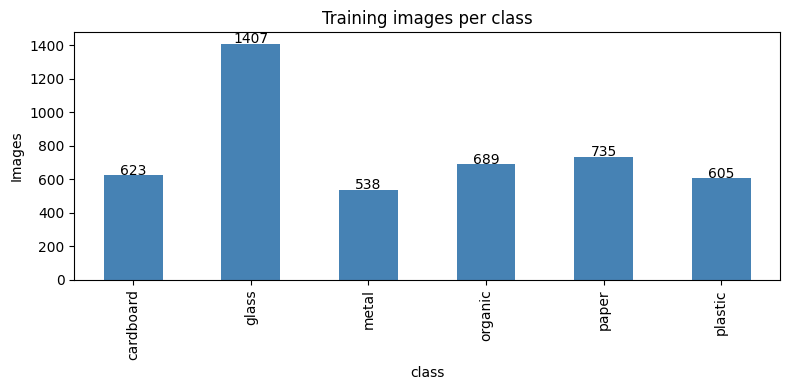

Imbalance ratio (max/min): 2.62


In [4]:
train_counts = df_counts[df_counts.split == 'train'].set_index('class')['count']
ax = train_counts.plot(kind='bar', figsize=(8, 4), color='steelblue')
ax.set_title('Training images per class'); ax.set_ylabel('Images')
for i, v in enumerate(train_counts): ax.text(i, v + 5, str(v), ha='center')
plt.tight_layout(); plt.show()
print('Imbalance ratio (max/min):', round(train_counts.max() / train_counts.min(), 2))

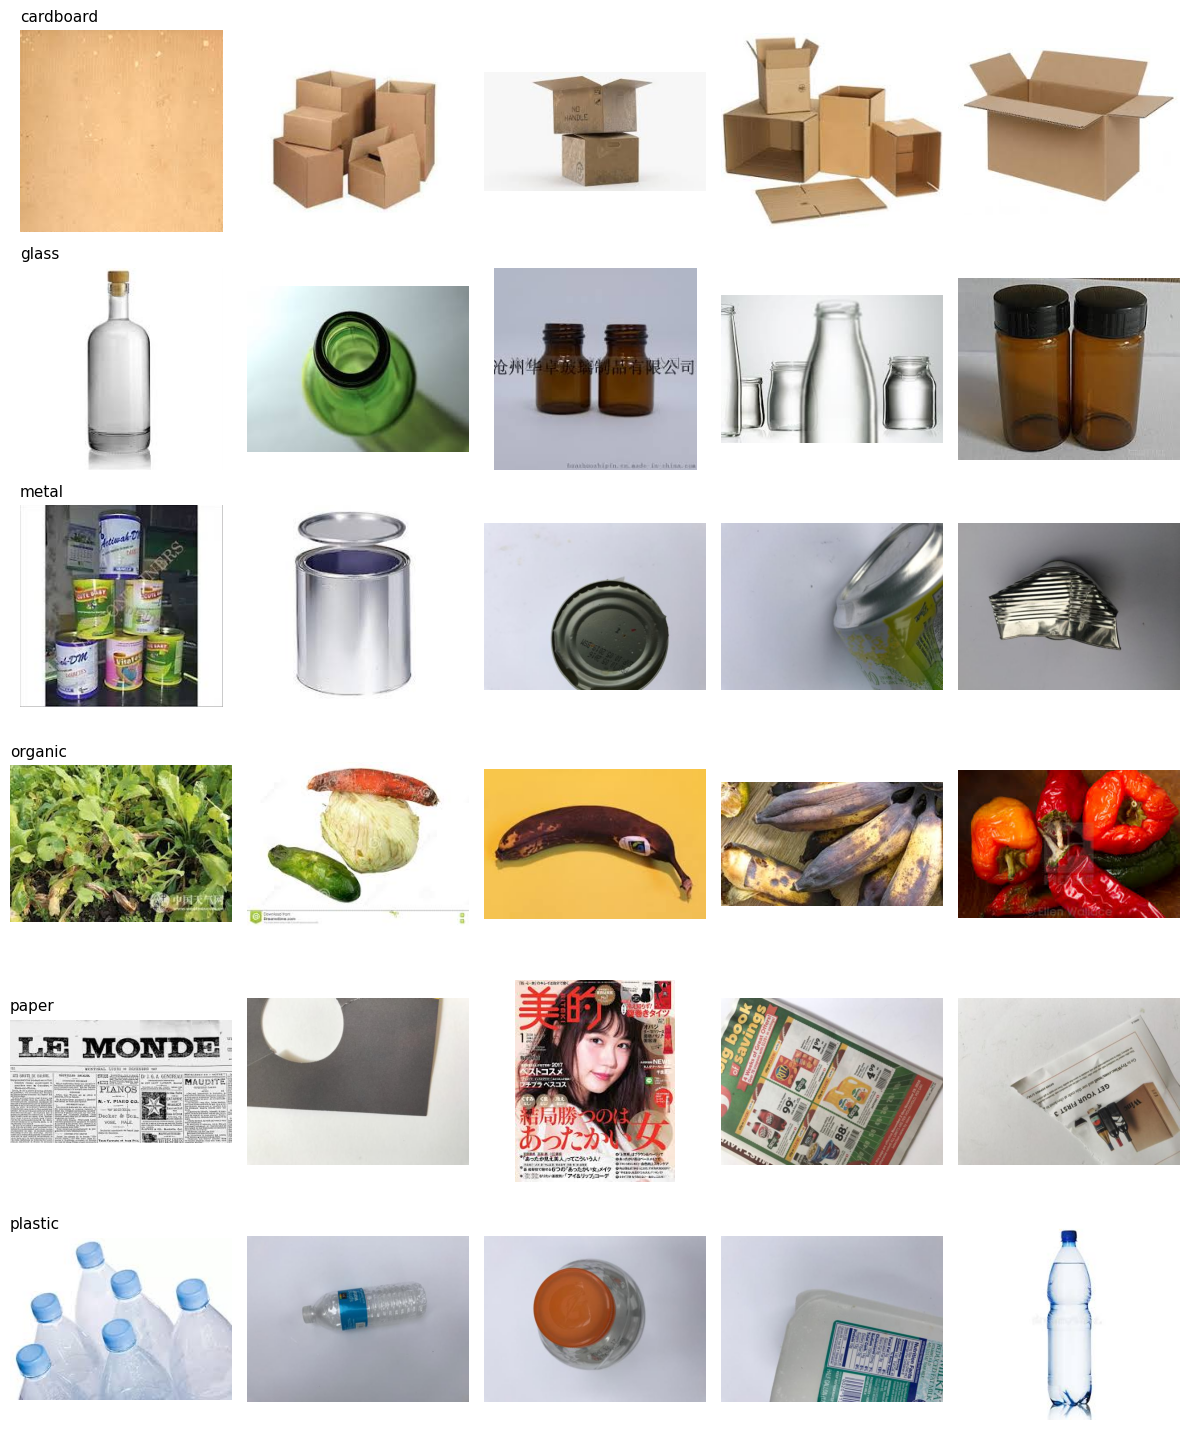

In [5]:
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(12, 2.4 * len(CLASSES)))
for r, cls in enumerate(CLASSES):
    files = random.sample(list((DST/'train'/cls).glob('*')), 5)
    for c, f in enumerate(files):
        axes[r, c].imshow(Image.open(f).convert('RGB')); axes[r, c].axis('off')
        if c == 0: axes[r, c].set_title(cls, loc='left', fontsize=11)
plt.tight_layout(); plt.show()

                w               h        aspect      
             mean     std    mean    std   mean   std
class                                                
cardboard  370.62  130.73  282.86  93.74   1.32  0.24
glass      291.93  126.86  265.14  72.29   1.09  0.26
metal      406.81  132.99  312.50  90.09   1.31  0.38
organic    265.70   37.62  192.55  29.16   1.43  0.41
paper      401.83  141.68  322.87  81.23   1.24  0.31
plastic    406.21  135.86  318.71  85.57   1.28  0.29


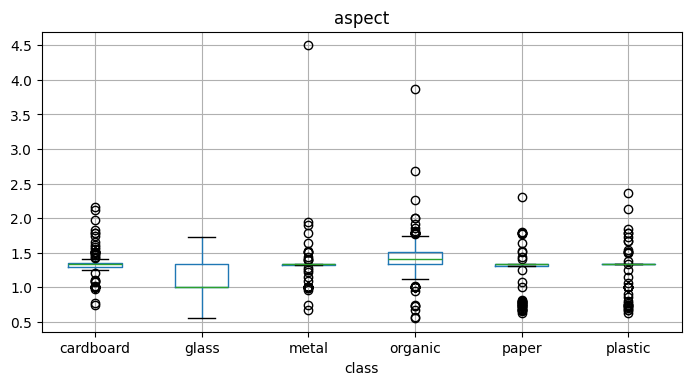

In [6]:
recs = []
for cls in CLASSES:
    for f in random.sample(list((DST/'train'/cls).glob('*')), 100):
        w, h = Image.open(f).size
        recs.append((cls, w, h, w / h))
df_size = pd.DataFrame(recs, columns=['class', 'w', 'h', 'aspect'])
print(df_size.groupby('class')[['w', 'h', 'aspect']].agg(['mean', 'std']).round(2))
df_size.boxplot(column='aspect', by='class', figsize=(8, 4)); plt.suptitle(''); plt.show()

           brightness           R           G           B
class                                                    
cardboard  169.100006  191.699997  169.800003  145.800003
glass      177.800003  182.199997  182.199997  169.100006
metal      167.199997  172.199997  166.100006  163.300003
organic    148.699997  175.000000  149.000000  121.900002
paper      167.800003  175.899994  168.000000  159.500000
plastic    182.699997  181.300003  183.399994  183.399994


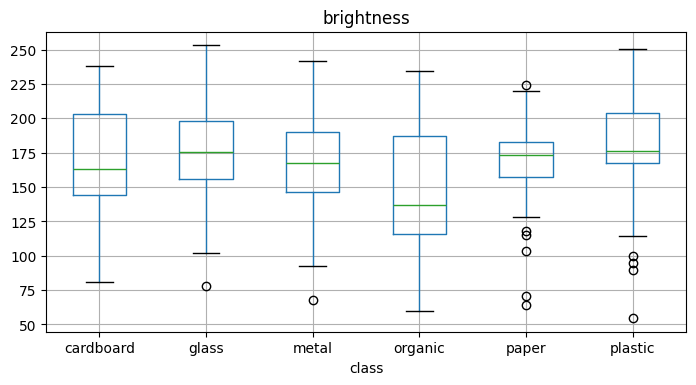

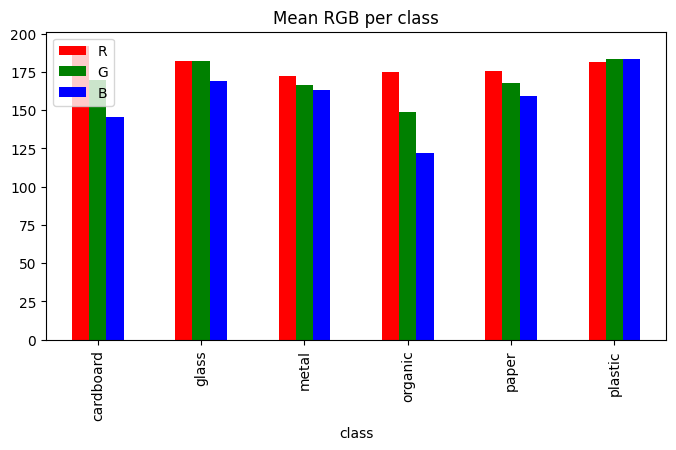

In [7]:
recs = []
for cls in CLASSES:
    for f in random.sample(list((DST/'train'/cls).glob('*')), 100):
        a = np.asarray(Image.open(f).convert('RGB').resize((64, 64)), dtype=np.float32)
        recs.append((cls, a.mean(), *a.mean(axis=(0, 1))))
df_col = pd.DataFrame(recs, columns=['class', 'brightness', 'R', 'G', 'B'])
print(df_col.groupby('class').mean().round(1))
df_col.boxplot(column='brightness', by='class', figsize=(8, 4)); plt.suptitle(''); plt.show()
df_col.groupby('class')[['R', 'G', 'B']].mean().plot(kind='bar', color=['r', 'g', 'b'], figsize=(8, 4))
plt.title('Mean RGB per class'); plt.show()

# 4. Preprocessing: resize to 224x224, normalize for MobileNetV2, and augmentation

In [8]:
import sys

!git clone https://github.com/ShamiPlacide/SortFlow.git /kaggle/working/waste-classifier
sys.path.insert(0, '/kaggle/working/waste-classifier')

import tensorflow as tf
print(tf.__version__, tf.config.list_physical_devices('GPU'))

Cloning into '/kaggle/working/waste-classifier'...
remote: Enumerating objects: 41, done.
remote: Counting objects: 100% (41/41), done.
remote: Compressing objects: 100% (27/27), done.
remote: Total 41 (delta 9), reused 32 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (41/41), 1.45 MiB | 23.27 MiB/s, done.
Resolving deltas: 100% (9/9), done.
2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [9]:

from data.test.src.preprocessing import load_dataset, compute_class_weights

In [10]:
train_ds, class_names = load_dataset(DST/'train', shuffle=True, augment=True)
val_ds, _ = load_dataset(DST/'val', class_names=class_names)
print(class_names)
print(compute_class_weights(DST/'train'))

Found 4597 files belonging to 6 classes.
Found 986 files belonging to 6 classes.
['cardboard', 'glass', 'metal', 'organic', 'paper', 'plastic']
{0: np.float64(1.2298020331728197), 1: np.float64(0.5445392087183132), 2: np.float64(1.424101610904585), 3: np.float64(1.1119980648282535), 4: np.float64(1.0424036281179139), 5: np.float64(1.2663911845730027)}


In [11]:
!cd /content/waste-classifier && git pull

/bin/bash: line 1: cd: /content/waste-classifier: No such file or directory


# 5. Model, evaluation, and saving

In [12]:
# Step 2: Baseline model
import tensorflow as tf
from data.test.src.model import build_baseline
from data.test.src.preprocessing import load_dataset, compute_class_weights

train_ds, class_names = load_dataset(DST/'train', shuffle=True, augment=False)
val_ds, _ = load_dataset(DST/'val', class_names=class_names)
test_ds, _ = load_dataset(DST/'test', class_names=class_names)

baseline = build_baseline(len(class_names))
hist_base = baseline.fit(train_ds, validation_data=val_ds, epochs=10)

Found 4597 files belonging to 6 classes.
Found 986 files belonging to 6 classes.
Found 988 files belonging to 6 classes.
Epoch 1/10
144/144 ━━━━━━━━━━━━━━━━━━━━ 22s 96ms/step - accuracy: 0.4283 - loss: 2.0770 - precision: 0.6315 - recall: 0.2069 - val_accuracy: 0.5446 - val_loss: 1.3280 - val_precision: 0.7872 - val_recall: 0.2252
Epoch 2/10
144/144 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.6141 - loss: 1.0652 - precision: 0.7966 - recall: 0.4251 - val_accuracy: 0.5548 - val_loss: 1.2328 - val_precision: 0.7199 - val_recall: 0.3884
Epoch 3/10
144/144 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.7377 - loss: 0.7645 - precision: 0.8790 - recall: 0.5865 - val_accuracy: 0.5710 - val_loss: 1.4828 - val_precision: 0.6281 - val_recall: 0.5122
Epoch 4/10
144/144 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.8323 - loss: 0.5011 - precision: 0.9168 - recall: 0.7290 - val_accuracy: 0.5811 - val_loss: 1.5013 - val_precision: 0.6447 - val_recall: 0.5152
Epoch 5/10
144/144 ━━━━━━━━━━━━━━━

In [14]:
# Step 3: Custom optimized model
train_aug, _ = load_dataset(DST/'train', shuffle=True, augment=True, class_names=class_names)
class_weights = compute_class_weights(DST/'train')

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
    tf.keras.callbacks.ModelCheckpoint('/kaggle/working/best_custom.keras',
                                       monitor='val_loss', save_best_only=True),
]

Found 4597 files belonging to 6 classes.


In [15]:
!cd /kaggle/working/waste-classifier && git pull

Already up to date.


In [17]:
from data.test.src.model import build_custom

callbacks[0] = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
model = build_custom(len(class_names))
hist = model.fit(train_aug, validation_data=val_ds, epochs=60, callbacks=callbacks)
# model = build_custom(len(class_names))
# hist = model.fit(train_aug, validation_data=val_ds, epochs=40,
                 # class_weight=class_weights, callbacks=callbacks)

Epoch 1/60


E0000 00:00:1795592930.466265     156 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795592932.476244     156 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795592940.009741     156 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.4592 - loss: 1.4412 - precision: 0.6118 - recall: 0.2466

E0000 00:00:1795592985.215017     156 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795592986.882041     156 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795592990.927188     156 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


144/144 ━━━━━━━━━━━━━━━━━━━━ 87s 376ms/step - accuracy: 0.5090 - loss: 1.3008 - precision: 0.6782 - recall: 0.3228 - val_accuracy: 0.1836 - val_loss: 1.9950 - val_precision: 0.1935 - val_recall: 0.0913 - learning_rate: 0.0010
Epoch 2/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 30s 202ms/step - accuracy: 0.5680 - loss: 1.1552 - precision: 0.7231 - recall: 0.3970 - val_accuracy: 0.2475 - val_loss: 1.8569 - val_precision: 0.2635 - val_recall: 0.0396 - learning_rate: 0.0010
Epoch 3/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 29s 194ms/step - accuracy: 0.5969 - loss: 1.0936 - precision: 0.7413 - recall: 0.4357 - val_accuracy: 0.4939 - val_loss: 1.3322 - val_precision: 0.6218 - val_recall: 0.3884 - learning_rate: 0.0010
Epoch 4/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 28s 190ms/step - accuracy: 0.6161 - loss: 1.0456 - precision: 0.7439 - recall: 0.4575 - val_accuracy: 0.3671 - val_loss: 2.0304 - val_precision: 0.4340 - val_recall: 0.3134 - learning_rate: 0.0010
Epoch 5/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 30s 205ms/step - accura

In [19]:
import json
model.save('/kaggle/working/waste_cnn.h5')
json.dump(class_names, open('/kaggle/working/class_names.json', 'w'))

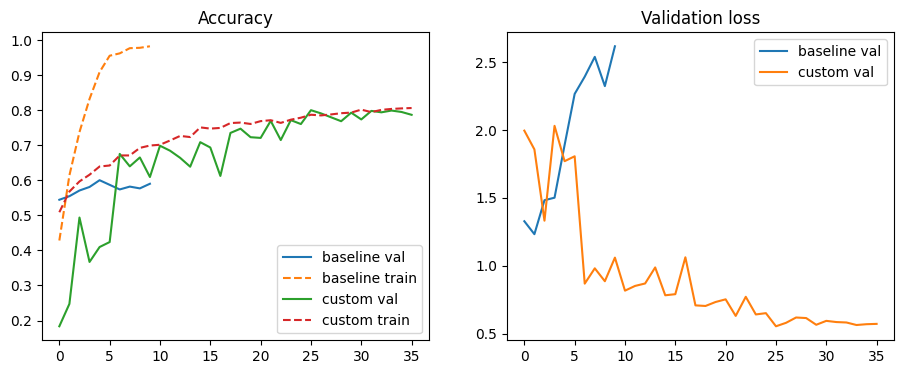

In [21]:
# Step 4: Training curves
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, h in [('baseline', hist_base), ('custom', hist)]:
    ax[0].plot(h.history['val_accuracy'], label=f'{name} val')
    ax[0].plot(h.history['accuracy'], '--', label=f'{name} train')
    ax[1].plot(h.history['val_loss'], label=f'{name} val')
ax[0].set_title('Accuracy'); ax[1].set_title('Validation loss')
ax[0].legend(); ax[1].legend(); plt.show()


== Baseline CNN ==
loss=2.199 acc=0.593 precision=0.614 recall=0.576
              precision    recall  f1-score   support

   cardboard      0.720     0.709     0.714       134
       glass      0.658     0.636     0.646       302
       metal      0.419     0.267     0.326       116
     organic      0.645     0.723     0.682       148
       paper      0.533     0.620     0.573       158
     plastic      0.450     0.485     0.467       130

    accuracy                          0.593       988
   macro avg      0.571     0.573     0.568       988
weighted avg      0.589     0.593     0.588       988



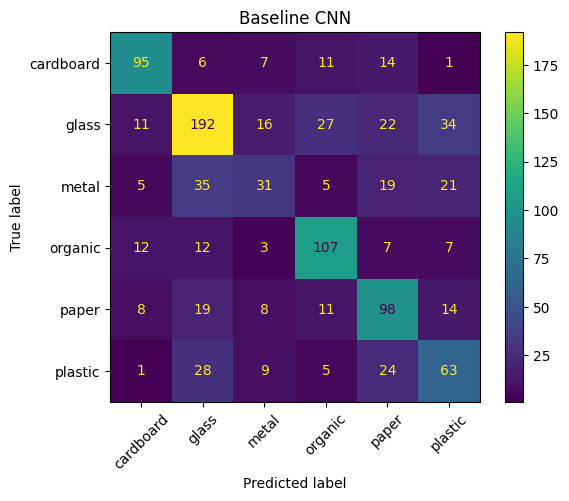


== Custom CNN ==
loss=0.542 acc=0.817 precision=0.877 recall=0.745
              precision    recall  f1-score   support

   cardboard      0.880     0.873     0.876       134
       glass      0.807     0.858     0.831       302
       metal      0.788     0.578     0.667       116
     organic      0.931     0.905     0.918       148
       paper      0.751     0.880     0.810       158
     plastic      0.758     0.700     0.728       130

    accuracy                          0.817       988
   macro avg      0.819     0.799     0.805       988
weighted avg      0.818     0.817     0.814       988



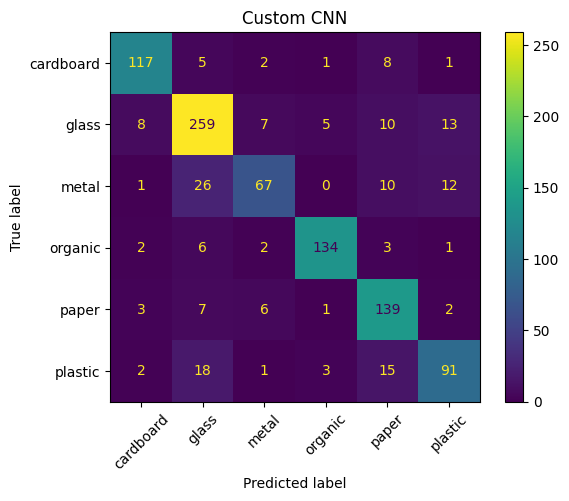

In [23]:
# Step 5: Evaluation on the test set
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

def evaluate(m, name):
    y_true = np.concatenate([y.numpy().argmax(1) for _, y in test_ds])
    y_prob = m.predict(test_ds, verbose=0)
    y_pred = y_prob.argmax(1)
    loss, acc, prec, rec = m.evaluate(test_ds, verbose=0)
    print(f'\n== {name} ==\nloss={loss:.3f} acc={acc:.3f} precision={prec:.3f} recall={rec:.3f}')
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot(xticks_rotation=45)
    plt.title(name); plt.show()

evaluate(baseline, 'Baseline CNN')
evaluate(model, 'Custom CNN')

In [ ]:
print('epochs run:', len(hist.history['loss']))
print('train acc:', hist.history['accuracy'][-1], 'val acc:', hist.history['val_accuracy'][-1])

In [24]:
print(tf.__version__)

2.21.0
